# Bornholm 2035 · What the original 15 runs tell us

**Provisional analysis of the final-v1 campaign.** All 15 solved networks were read in the earlier notebooks and flagged for numerical review. This notebook uses their rounded saved tables, so it can run without a Sophia transfer or a PyPSA solve. All costs and prices are real 2025 euros. The system-cost changes always use the no-island reference from the same pathway.

The design decision and the investment decision use different comparisons. The no-island runs ask whether to build. The split-radial runs ask how to connect the same 3 GW. The original split radial and hybrid also differ in the Danish cable rating, so the comparison combines flexible routing and the extra 200 MW. The [matched array](../bornholm_2035_campaign.md#central-matched-cable-experiment) isolates these two effects.

**Evidence.** The input tables below come from the executed `Bornholm_2035_Local_Results(2).ipynb` (system cost per MWh, CfD support, project rent and capture prices, zonal prices, and screening status) and `Bornholm_2035_National_Welfare(1).ipynb` (eight national welfare comparisons and their reconciliation). The table cells preserve the printed precision. The earlier welfare ledger pools project cable costs and congestion rents in equal shares. The €75/MWh benchmark assigns 70% of candidate CfD funding or repayments to Germany in both designs.


In [1]:
import sys
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

repo = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "scripts/assess_bornholm_agreement.py").is_file()
)
sys.path.insert(0, str(repo))
from scripts.assess_bornholm_agreement import AgreementCase, Participation, summarise

In [2]:
cases = pd.read_csv(StringIO("""
case,use_twh,total_cost_bn,total_cost_eur_mwh,cost_delta_m,cost_delta_regional_eur_mwh,cost_delta_bornholm_eur_mwh,hub,hub_de,hub_dk,DE,DK1,DK2,cable_rent_m,wind_twh,capture_price,wind_cost_recovery,status,screening_issues
central_baseline,4192.706,540.618,128.942,0.0,0.0,,,,,88.52,79.89,84.2,0.0,0.0,,,optimal_needs_review,ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05
central_hybrid,4192.751,540.784,128.981,165.744,0.04,11.761,80.29,,,88.17,79.81,82.95,125.48,14.09,68.55,64.65,optimal_needs_review,ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05
central_radial_de,4192.776,540.747,128.971,129.601,0.031,9.442,86.06,,,88.18,79.75,84.07,0.0,13.73,80.22,66.38,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
central_radial_dk,4193.094,541.01,129.024,392.418,0.094,27.214,70.43,,,88.41,79.72,72.25,0.0,14.42,52.22,63.19,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
central_split_radial,4192.809,540.802,128.983,184.509,0.044,13.217,,86.09,78.78,88.2,79.71,80.81,0.0,13.96,75.28,65.27,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
ev55_baseline,4282.607,522.801,122.075,0.0,0.0,,,,,85.71,78.27,81.37,0.0,0.0,,,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05 | DualResidual missing or exceeds screening threshold 1e-05
ev55_hybrid,4281.963,522.988,122.138,187.587,0.044,13.231,78.13,,,85.63,78.08,80.22,114.15,14.18,67.66,64.27,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
ev55_split_radial,4282.194,523.002,122.134,201.365,0.047,14.301,,83.57,75.93,85.62,77.56,77.88,0.0,14.08,73.58,64.71,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
ev65_baseline,4445.435,508.26,114.333,0.0,0.0,,,,,84.8,78.03,80.05,0.0,0.0,,,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
ev65_hybrid,4445.33,508.462,114.381,201.306,0.045,14.093,77.46,,,84.76,77.74,78.69,102.95,14.28,67.06,63.79,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
ev65_split_radial,4445.475,508.468,114.379,207.658,0.047,14.562,,82.74,75.1,84.78,77.66,77.04,0.0,14.26,72.33,63.9,optimal_needs_review,DualVio missing or exceeds screening threshold 1e-05
v2g0_baseline,4185.484,546.49,130.568,0.0,0.0,,,,,87.96,80.35,84.52,0.0,0.0,,,optimal_needs_review,ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05
v2g0_hybrid,4185.161,546.67,130.621,180.02,0.043,12.782,79.88,,,87.76,79.89,82.79,126.97,14.08,67.4,64.7,optimal_needs_review,ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05 | DualResidual missing or exceeds screening threshold 1e-05
v2g50_baseline,4196.185,541.102,128.951,0.0,0.0,,,,,88.81,80.03,84.32,0.0,0.0,,,optimal_needs_review,ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05
v2g50_hybrid,4196.545,541.267,128.979,164.764,0.039,11.651,80.45,,,88.27,79.83,82.96,122.87,14.14,68.48,64.43,optimal_needs_review,ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05
"""), index_col="case")
support = pd.read_csv(StringIO("""
case,75.0,82.5,90.0,97.5
central_baseline,0.0,0.0,0.0,0.0
central_hybrid,90.94,196.64,302.33,408.03
central_radial_de,-71.68,31.26,134.2,237.15
central_radial_dk,328.43,436.58,544.73,652.88
central_split_radial,-3.84,100.86,205.56,310.25
ev55_baseline,0.0,0.0,0.0,0.0
ev55_hybrid,104.13,210.47,316.8,423.14
ev55_split_radial,20.01,125.62,231.22,336.83
ev65_baseline,0.0,0.0,0.0,0.0
ev65_hybrid,113.45,220.58,327.71,434.85
ev65_split_radial,38.07,145.03,251.98,358.93
v2g0_baseline,0.0,0.0,0.0,0.0
v2g0_hybrid,107.07,212.7,318.32,423.95
v2g50_baseline,0.0,0.0,0.0,0.0
v2g50_hybrid,92.23,198.28,304.34,410.4
"""), index_col="case")
ledger = pd.read_csv(StringIO("""
pathway,reference,DK,DE,developer,other,system
central,baseline,-142.44,-103.3,145.81,-65.82,-165.7443
central,split_radial,4.78,-9.23,9.99,13.23,18.7651
ev55,baseline,-154.26,-139.05,152.2,-46.47,-187.5872
ev55,split_radial,8.1,-19.67,7.3,18.05,13.778
ev65,baseline,-158.48,-176.7,160.17,-26.3,-201.3063
ev65,split_radial,6.44,-17.96,1.82,16.05,6.3519
v2g0,baseline,-142.7,-149.0,145.11,-33.43,-180.0202
v2g50,baseline,-142.54,-57.86,149.42,-113.79,-164.7638
"""))
check = ledger[["DK", "DE", "developer", "other"]].sum(axis=1) - ledger.system
assert len(cases) == 15 and cases.index.is_unique and len(ledger) == 8
assert check.abs().max() < 0.03, "Rounded country accounts failed to reconcile"
print(f"{len(cases)} cases and {len(ledger)} welfare comparisons. Worst rounded ledger residual: €{check.abs().max():.4f}m/year.")

15 cases and 8 welfare comparisons. Worst rounded ledger residual: €0.0072m/year.


## 1. System costs and project economics

Central, EV55 and EV65 each have no island, treaty hybrid and split radial. Central also tests 3 GW radial to Denmark and 3 GW radial to Germany. V2G0 and V2G50 each have no island and treaty hybrid. EV55 and EV65 change mobility, industrial transition and data-centre demand together. The V2G runs vary the availability of discharge while retaining managed charging.

In [3]:
overview = cases[["cost_delta_m", "wind_twh", "capture_price", "wind_cost_recovery", "cable_rent_m", "DK1", "DK2", "DE"]].join(support["75.0"])
overview.columns = ["Δ system cost €m/y", "Wind TWh/y", "Capture €/MWh", "Wind cost recovery €/MWh",
                    "Cable rent €m/y", "DK1 price", "DK2 price", "DE price", "CfD at €75 €m/y"]
display(overview.round(2))
print("Original numerical screening")
display(cases[["status", "screening_issues"]])

Original numerical screening


                      Δ system cost €m/y  Wind TWh/y  Capture €/MWh  Wind cost recovery €/MWh  Cable rent €m/y  DK1 price  DK2 price  DE price  CfD at €75 €m/y
case                                                                                                                                                           
central_baseline                    0.00        0.00            NaN                       NaN             0.00      79.89      84.20     88.52             0.00
central_hybrid                    165.74       14.09          68.55                     64.65           125.48      79.81      82.95     88.17            90.94
central_radial_de                 129.60       13.73          80.22                     66.38             0.00      79.75      84.07     88.18           -71.68
central_radial_dk                 392.42       14.42          52.22                     63.19             0.00      79.72      72.25     88.41           328.43
central_split_radial              184.51

                                    status                                                                                                                                                           screening_issues
case                                                                                                                                                                                                                 
central_baseline      optimal_needs_review                                                              ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05
central_hybrid        optimal_needs_review                                                              ConstrVio missing or exceeds screening threshold 0.001 | DualVio missing or exceeds screening threshold 1e-05
central_radial_de     optimal_needs_review                                                                                                      

In [4]:
costs = cases.cost_delta_m.rename_axis("case").reset_index()
costs[["pathway", "design"]] = costs.case.str.split("_", n=1, expand=True)
by_design = costs.pivot(index="pathway", columns="design", values="cost_delta_m")
comparison = pd.DataFrame({
    "Hybrid cost vs no island": by_design.hybrid,
    "Hybrid saving vs split radial": by_design.split_radial - by_design.hybrid,
})
display(comparison.round(2))
display(support)


         Hybrid cost vs no island  Hybrid saving vs split radial
pathway                                                         
central                    165.74                          18.76
ev55                       187.59                          13.78
ev65                       201.31                           6.35
v2g0                       180.02                            NaN
v2g50                      164.76                            NaN

                        75.0    82.5    90.0    97.5
case                                                
central_baseline        0.00    0.00    0.00    0.00
central_hybrid         90.94  196.64  302.33  408.03
central_radial_de     -71.68   31.26  134.20  237.15
central_radial_dk     328.43  436.58  544.73  652.88
central_split_radial   -3.84  100.86  205.56  310.25
ev55_baseline           0.00    0.00    0.00    0.00
ev55_hybrid           104.13  210.47  316.80  423.14
ev55_split_radial      20.01  125.62  231.22  336.83
ev65_baseline           0.00    0.00    0.00    0.00
ev65_hybrid           113.45  220.58  327.71  434.85
ev65_split_radial      38.07  145.03  251.98  358.93
v2g0_baseline           0.00    0.00    0.00    0.00
v2g0_hybrid           107.07  212.70  318.32  423.95
v2g50_baseline          0.00    0.00    0.00    0.00
v2g50_hybrid           92.23  198.28  304.34  410.40

Across the five pathways, the treaty hybrid adds **€165–201m/year** to system cost relative to no island. Relative to split radial, it saves **€18.77m, €13.78m and €6.35m/year** under central, EV55 and EV65 assumptions. Those are paired differences. At central demand, radial to Germany alone is the least-cost build option modelled, at **€129.60m/year** above no island. That option changes who receives the connection, so assess it separately from a design decision that requires both landings.

Under faster transition, the hybrid's capture price falls **€68.55 → €67.06/MWh** while output rises **14.09 → 14.28 TWh/year**. Gross project cable rent falls **€125.48m → €102.95m/year**. At a €75 strike, CfD support rises **€90.94m → €113.45m/year**. These are sensitivities to the whole pathway. Higher EV share alone cannot be inferred to cause them. Modelled wind cost recovery is an annual generation-cost diagnostic. A financeable strike needs a separate project cash-flow assessment.


With V2G disabled, the hybrid costs **€180.02m/year** more than its no-island
case. At 50% V2G availability, the premium is **€164.76m/year**, close to the
central V2G25 result of **€165.74m/year**. The original runs therefore give a
V2G sensitivity for the investment decision.

## 2. Apply the same agreement across the available futures

Use the existing CfD screen for the three matched split-radial comparisons. Each radial reference retains the €75/MWh strike and 70% German share used in the saved ledger. Recalculate the *candidate* contract only. Rounded annual generation and the saved €75/MWh settlement recover the implied capture price at the anchor. The developer must match its modelled radial outcome. Both countries must at least match their radial welfare. No tighter funding caps are imposed in this illustrative screen.

The first table tests each future independently. Next, take the central equal-gain agreement and hold it fixed under EV55 and EV65. This evaluates the same agreement across futures. No V2G split-radial network is available, so the V2G cases enter only the no-island comparisons.


Fixed central agreement: €74.291/MWh and 63.81% German funding.


                          DK      DE  developer   other  system
pathway reference                                              
central baseline     -142.44 -103.30     145.81  -65.82 -165.74
        split_radial    4.78   -9.23       9.99   13.23   18.77
ev55    baseline     -154.26 -139.05     152.20  -46.47 -187.59
        split_radial    8.10  -19.67       7.30   18.05   13.78
ev65    baseline     -158.48 -176.70     160.17  -26.30 -201.31
        split_radial    6.44  -17.96       1.82   16.05    6.35
v2g0    baseline     -142.70 -149.00     145.11  -33.43 -180.02
v2g50   baseline     -142.54  -57.86     149.42 -113.79 -164.76

         participation_surplus  variable_share_feasible  variable_share_min_strike  variable_share_max_strike  fixed_70_percent_de_feasible
pathway                                                                                                                                    
central                   5.54                     True                     74.291                     74.684                         False
ev55                     -4.27                    False                        NaN                        NaN                         False
ev65                     -9.70                    False                        NaN                        NaN                         False

         Denmark  Germany  Developer  total_support_m
central     2.77     2.77       0.00            80.95
ev55        5.30    -6.81      -2.75            94.08
ev65        3.09    -4.48      -8.30           103.33

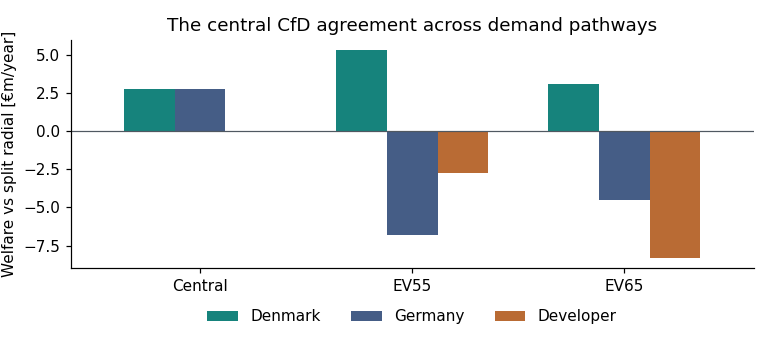

In [5]:
display(ledger.set_index(["pathway", "reference"]).round(2))

requirements = Participation()
agreements = {}
rows = []
for row in ledger.query("reference == 'split_radial'").itertuples(index=False):
    key = row.pathway + "_hybrid"
    generation = cases.at[key, "wind_twh"]
    capture = 75 - support.at[key, "75.0"] / generation
    case = AgreementCase.from_anchor(generation, capture, row.DK, row.DE, row.developer)
    agreements[row.pathway] = case
    rows.append({"pathway": row.pathway, **summarise(case, requirements)})

screen = pd.DataFrame(rows).set_index("pathway")
display(screen[["participation_surplus", "variable_share_feasible", "variable_share_min_strike",
                "variable_share_max_strike", "fixed_70_percent_de_feasible"]].round(3))

central = screen.loc["central"]
print(f"Fixed central agreement: €{central.strike:.3f}/MWh and {central.german_share:.2%} German funding.")
fixed = pd.DataFrame({
    world: case.settlement(central.strike, central.german_share)
    for world, case in agreements.items()
}).T
gains = fixed[["dk_gain", "de_gain", "developer_gain"]].rename(columns={
    "dk_gain": "Denmark", "de_gain": "Germany", "developer_gain": "Developer",
})
assert (gains.sum(axis=1) - screen.participation_surplus).abs().max() < 1e-8
display(gains.assign(total_support_m=fixed.net_support).round(2))

ax = gains.rename(index={"central": "Central", "ev55": "EV55", "ev65": "EV65"}).plot.bar(
    color=["#16837C", "#455D86", "#B96B34"], width=0.72, figsize=(7, 3.2), rot=0
)
ax.axhline(0, color="#505861", linewidth=0.8)
ax.set(title="The central CfD agreement across demand pathways",
       ylabel="Welfare vs split radial [€m/year]", xlabel="")
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.spines[["right", "top"]].set_visible(False)
ax.figure.tight_layout()
plt.show()

## What we can take into the decision assessment

- **Central demand gives some room to renegotiate.** Under the annual proxy, a flexible German share supports a narrow strike range of **€74.29–74.68/MWh**. A fixed 70% German share gives no feasible strike with all three floors. The central equal-gain benchmark is illustrative and sits at the developer's assumed floor.
- **EV55 and EV65 rule out a single passing agreement across these three pathways under the stated floors.** Even allowing the strike and support share to vary independently by pathway, the sum of Danish, German and developer gains is **−€4.27m and −€9.70m/year**. Transfers within that group cannot cover the shortfall. The earliest conclusion we can draw for sequencing is that optimising the CfD after fixing this grid cannot solve this problem under those assumptions. Whether an alternative grid helps is the next test.
- **Holding the central terms fixed makes the stress tangible.** Germany falls to **−€6.81m/year** in EV55 and **−€4.48m/year** in EV65. The developer is also below its radial hurdle in both cases, by **€2.75m** and **€8.30m/year**. Denmark remains ahead in this pooled-cost calculation.
- **Positive system gains and negative gains to project participants can coexist.** The ledger attributes some gains to other territories or unallocated accounts. That residual cannot automatically be treated as an available contribution. Cost ownership also changes which government bears the burden. The new matched analysis will report pooled and landing-country cable costs side by side.

The evidence here covers one model horizon, one weather year and an annual actual-output CfD proxy. Solver screening remains unresolved in these originals. The exact CfD terms, welfare allocation and small system-cost differences remain provisional pending the matched solves and their numerical checks.
